In [4]:
import pandas as pd
import nltk 
import numpy as np

In [5]:
df = pd.read_csv("sms_spam_classifier_data.csv", encoding='latin-1')

In [6]:
df.sample(5)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
5427,spam,Santa Calling! Would your little ones like a c...,NaN,NaN,NaN
482,ham,Watching tv lor...,NaN,NaN,NaN
4189,ham,"Sorry, I'll call later",NaN,NaN,NaN
251,ham,"Wen ur lovable bcums angry wid u, dnt take it ...",NaN,NaN,NaN
1508,ham,Sounds like something that someone testing me ...,NaN,NaN,NaN


In [7]:
df.drop(columns=['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], inplace=True)

In [8]:
df.rename(columns={'v1': 'output', 'v2': 'input_text'}, inplace=True)

In [9]:
df.sample(5)

,output,input_text
2001,ham,Idea will soon get converted to live:)
4414,ham,"Yeah I should be able to, I'll text you when I..."
3084,ham,In da car park
3649,ham,"We are hoping to get away by 7, from Langport...."
62,ham,Its a part of checking IQ


In [10]:
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Himanshu\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [11]:
df['characters'] = df['input_text'].apply(len)
df['words'] = df['input_text'].apply(lambda x: len(nltk.word_tokenize(x)))
df['sentences'] = df['input_text'].apply(lambda x: len(nltk.sent_tokenize(x)))

In [12]:
df.sample(5)

,output,input_text,characters,words,sentences
1328,ham,My exam is for february 4. Wish you a great day.,48,13,2
701,ham,"Sorry, I'll call later",22,6,1
4635,ham,K k pa Had your lunch aha.,26,8,1
3370,ham,Tomorrow i am not going to theatre. . . So i c...,117,29,7
2315,ham,That's significant but dont worry.,34,7,1


In [13]:
from nltk import PorterStemmer
ps = PorterStemmer()
ps.stem("loving")

'love'

In [14]:
import string
from nltk.corpus import stopwords

In [15]:
def transform_words(msg):
    msg = msg.lower()
    msg = nltk.word_tokenize(msg)

    y = []
    for i in msg:
        if i.isalnum():
            y.append(i)

    msg = y[:]
    y.clear()

    for i in msg:
        if i not in stopwords.words('english') and i not in string.punctuation:
            y.append(i)

    msg = y[:]
    y.clear()

    for i in msg:
        y.append(ps.stem(i))
    
    return " ".join(y)


In [16]:
transform_words("Hello, My name is Omkar")

'hello name omkar'

In [17]:
df['transformed_text'] = df['input_text'].apply(lambda x: transform_words(x))

In [18]:
df.sample(10)

,output,input_text,characters,words,sentences,transformed_text
2251,ham,hope things went well at 'doctors' ;) reminds ...,110,26,1,hope thing went well remind still need u c lit...
1592,ham,Will it help if we propose going back again to...,52,10,1,help propos go back tomorrow
3645,ham,Carlos says we can pick up from him later so y...,59,14,1,carlo say pick later yeah set
661,ham,Then mum's repent how?,22,6,1,mum repent
2501,ham,No da..today also i forgot..,28,8,1,da today also forgot
604,ham,Meet after lunch la...,22,5,1,meet lunch la
3573,ham,Yeah sure I'll leave in a min,29,8,1,yeah sure leav min
3758,ham,"GOD ASKED, \What is forgiveness?\"" A little ch...",67,15,1,god ask forgiv littl child gave love repli
4571,ham,Omg how did u know what I ate?,30,9,1,omg u know ate
3506,ham,Two fundamentals of cool life: \Walk,36,7,1,two fundament cool life


In [19]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()

In [20]:
df['output'] = encoder.fit_transform(df['output'])

In [21]:
df[df['output'] == 0].describe()

,output,characters,words,sentences
count,4825.0,4825.000000,4825.000000,4825.000000
mean,0.0,71.023627,17.276269,1.837720
std,0.0,58.016023,13.988585,1.454388
min,0.0,2.000000,1.000000,1.000000
25%,0.0,33.000000,8.000000,1.000000
50%,0.0,52.000000,13.000000,1.000000
75%,0.0,92.000000,22.000000,2.000000
max,0.0,910.000000,220.000000,38.000000


In [22]:
df[df['output'] == 1].describe()

,output,characters,words,sentences
count,747.0,747.000000,747.000000,747.000000
mean,1.0,138.866131,27.891566,3.021419
std,0.0,29.183082,6.867007,1.537580
min,1.0,13.000000,2.000000,1.000000
25%,1.0,132.500000,25.000000,2.000000
50%,1.0,149.000000,29.000000,3.000000
75%,1.0,157.000000,32.000000,4.000000
max,1.0,224.000000,46.000000,9.000000


In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

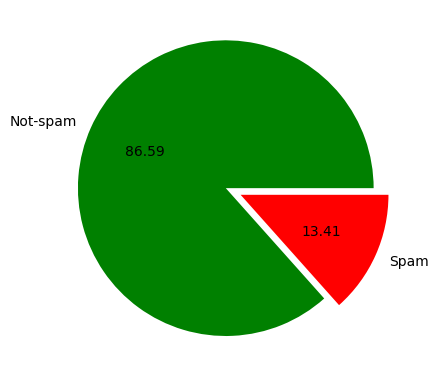

In [24]:
plt.pie(df['output'].value_counts(), labels=['Not-spam', 'Spam'], autopct="%0.2f", explode=[0.1, 0.01], colors=['green', 'red'])
plt.show()

<Axes: xlabel='characters', ylabel='Count'>

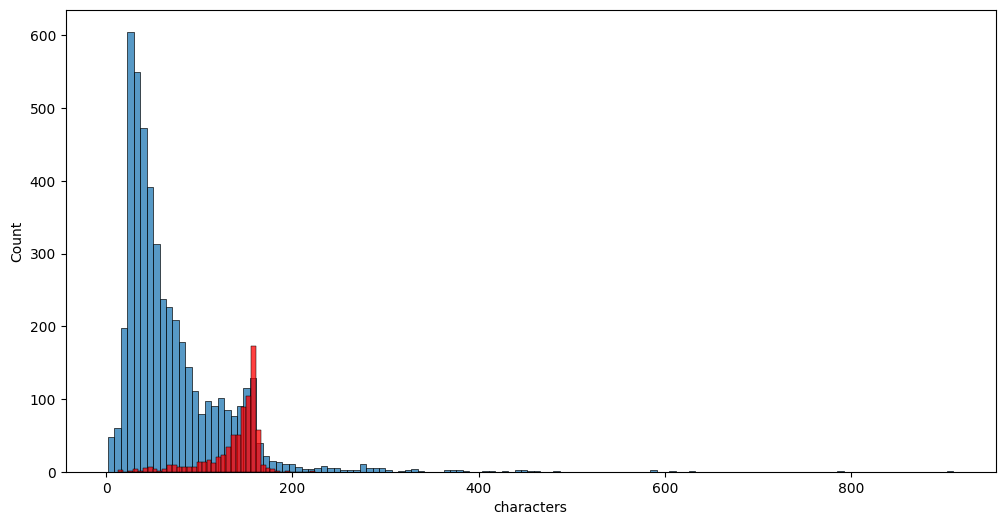

In [25]:
plt.figure(figsize=(12,6))
sns.histplot(df[df['output'] == 0]['characters'])
sns.histplot(df[df['output'] == 1]['characters'], color='red')


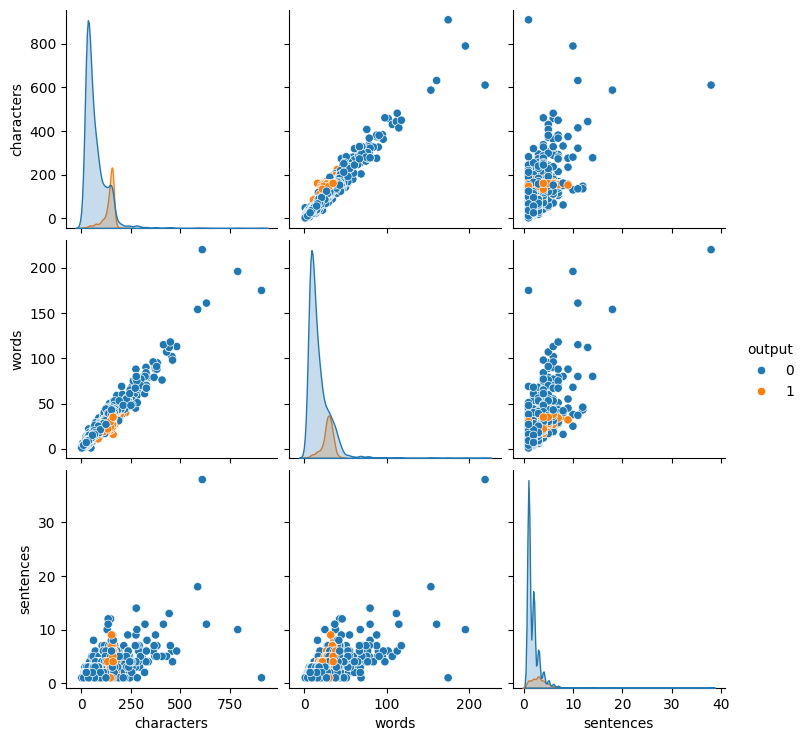

In [26]:
sns.pairplot(df, hue='output')

<Axes: >

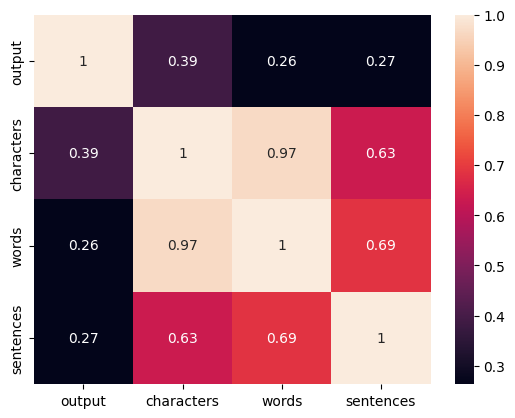

In [27]:
sns.heatmap(df[['output', 'characters', 'words', 'sentences']].corr(), annot=True)

In [28]:
from wordcloud import WordCloud
wc = WordCloud(width=500, height=500, background_color='black')

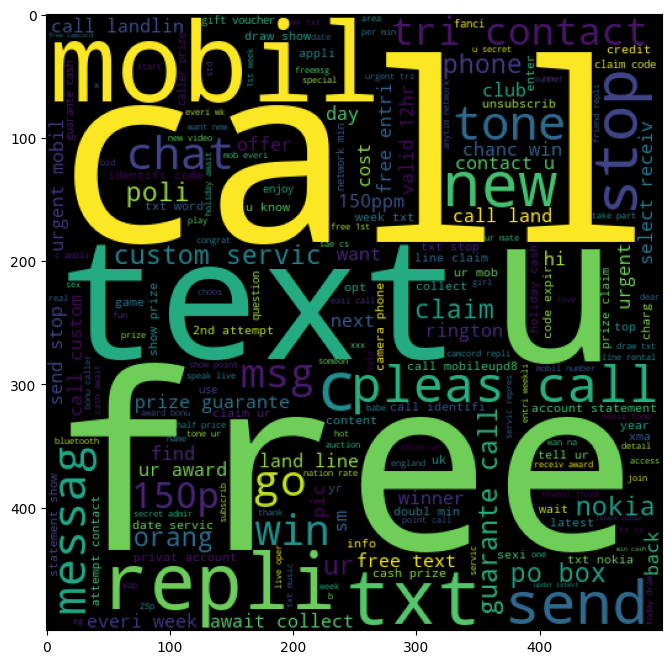

In [29]:
spam_wc = wc.generate(df[df['output'] == 1]['transformed_text'].str.cat(sep=" "))
plt.figure(figsize=(10,8))
plt.imshow(spam_wc)

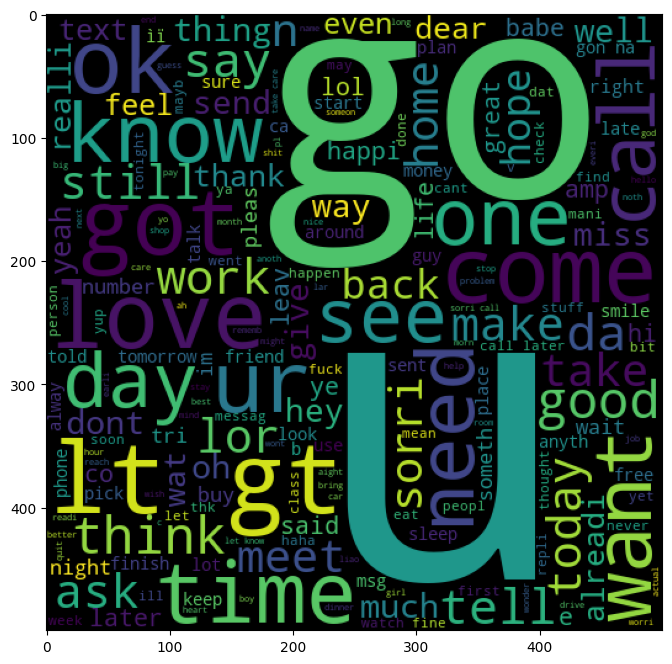

In [30]:
not_spam_wc = wc.generate(df[df['output'] == 0]['transformed_text'].str.cat(sep=" "))
plt.figure(figsize=(10,8))
plt.imshow(not_spam_wc)

In [31]:
spam_corpus = []
for msg in df[df["output"] == 1]["transformed_text"].tolist():
    for word in msg.split():
        spam_corpus.append(word)


In [32]:
print(len(spam_corpus))

11490


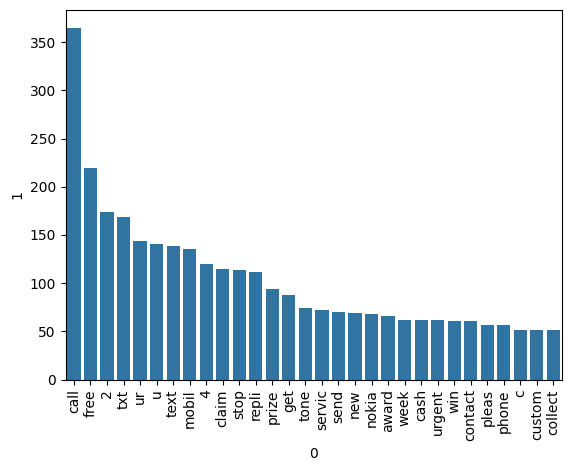

In [33]:
from collections import Counter
sns.barplot(x=pd.DataFrame(Counter(spam_corpus).most_common(30))[0], y=pd.DataFrame(Counter(spam_corpus).most_common(30))[1])
plt.xticks(rotation='vertical')
plt.show()

In [34]:
not_spam_corpus = []
for msg in df[df["output"] == 0]["transformed_text"].tolist():
    for word in msg.split():
        not_spam_corpus.append(word)

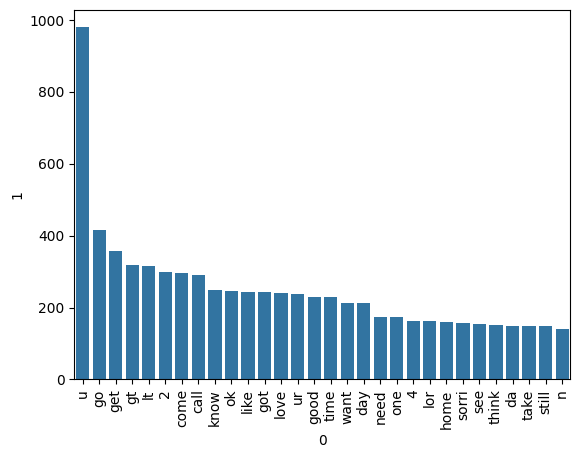

In [35]:
sns.barplot(x=pd.DataFrame(Counter(not_spam_corpus).most_common(30))[0], y=pd.DataFrame(Counter(not_spam_corpus).most_common(30))[1])
plt.xticks(rotation='vertical')
plt.show()

In [36]:
df.sample(5)

,output,input_text,characters,words,sentences,transformed_text
3155,0,Long time. You remember me today.,33,8,2,long time rememb today
5561,0,Get me out of this dump heap. My mom decided t...,70,18,3,get dump heap mom decid come low bore
3331,0,Ok... The theory test? when are Ì_ going to bo...,129,34,6,ok theori test go book think 21 may coz though...
2667,0,Why de. You looking good only:-)..,34,11,2,de look good
2040,0,You always make things bigger than they are,43,8,1,alway make thing bigger


In [37]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
cv = CountVectorizer()
tfidf = TfidfVectorizer()

In [38]:
x_cv = cv.fit_transform(df['transformed_text']).toarray()
x_tfidf = tfidf.fit_transform(df['transformed_text']).toarray()
y_values = df['output'].values

In [39]:
from sklearn.model_selection import train_test_split
x_cv_train, x_cv_test, y_cv_train, y_cv_test = train_test_split(
    x_cv,
    y_values,
    test_size=0.2,
    random_state=42
)

In [40]:
print(x_cv_train.shape, y_cv_train.shape)

(4457, 6708) (4457,)


In [41]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.metrics import accuracy_score, precision_score, confusion_matrix
gnb = GaussianNB()
mnb = MultinomialNB()
bnb = BernoulliNB()

In [42]:
gnb.fit(x_cv_train, y_cv_train)
pred_gnb = gnb.predict(x_cv_test)
print(accuracy_score(y_cv_test,pred_gnb))
print(precision_score(y_cv_test,pred_gnb))
print(confusion_matrix(y_cv_test,pred_gnb))

0.8609865470852018
0.4908424908424908
[[826 139]
 [ 16 134]]


In [43]:
mnb.fit(x_cv_train, y_cv_train)
pred_mnb = mnb.predict(x_cv_test)
print(accuracy_score(y_cv_test,pred_mnb))
print(precision_score(y_cv_test,pred_mnb))
print(confusion_matrix(y_cv_test,pred_mnb))

0.968609865470852
0.8758169934640523
[[946  19]
 [ 16 134]]


In [44]:
bnb.fit(x_cv_train, y_cv_train)
pred_bnb = bnb.predict(x_cv_test)
print(accuracy_score(y_cv_test,pred_bnb))
print(precision_score(y_cv_test,pred_bnb))
print(confusion_matrix(y_cv_test,pred_bnb))

0.967713004484305
0.9672131147540983
[[961   4]
 [ 32 118]]


In [45]:
x_tfidf_train, x_tfidf_test, y_tfidf_train, y_tfidf_test = train_test_split(
    x_tfidf,
    y_values,
    test_size=0.2,
    random_state=42
)

In [46]:
gnb.fit(x_tfidf_train, y_tfidf_train)
tfidf_pred_gnb = gnb.predict(x_tfidf_test)
print("Accuracy Score of Gaussian Naive Bayes with tfidf Vectorizer -> ", accuracy_score(y_tfidf_test, tfidf_pred_gnb))
print("Precision Score of Gaussian Naive Bayes with tfidf Vectorizer -> ", precision_score(y_tfidf_test, tfidf_pred_gnb))
print("Confusion Matrix of Gaussian Naive Bayes with tfidf Vectorizer -> ",confusion_matrix(y_tfidf_test, tfidf_pred_gnb))

Accuracy Score of Gaussian Naive Bayes with tfidf Vectorizer ->  0.8600896860986547
Precision Score of Gaussian Naive Bayes with tfidf Vectorizer ->  0.4889705882352941
Confusion Matrix of Gaussian Naive Bayes with tfidf Vectorizer ->  [[826 139]
 [ 17 133]]


In [47]:
mnb.fit(x_tfidf_train, y_tfidf_train)
tfidf_pred_mnb = mnb.predict(x_tfidf_test)
print("Accuracy Score of Multinomial Naive Bayes with tfidf Vectorizer -> ", accuracy_score(y_tfidf_test, tfidf_pred_mnb))
print("Precision Score of Multinomial Naive Bayes with tfidf Vectorizer -> ", precision_score(y_tfidf_test, tfidf_pred_mnb))
print("Confusion Matrix of Multinomial Naive Bayes with tfidf Vectorizer -> ",confusion_matrix(y_tfidf_test, tfidf_pred_mnb))

Accuracy Score of Multinomial Naive Bayes with tfidf Vectorizer ->  0.9632286995515695
Precision Score of Multinomial Naive Bayes with tfidf Vectorizer ->  1.0
Confusion Matrix of Multinomial Naive Bayes with tfidf Vectorizer ->  [[965   0]
 [ 41 109]]


In [48]:
bnb.fit(x_tfidf_train, y_tfidf_train)
tfidf_pred_bnb = bnb.predict(x_tfidf_test)
print("Accuracy Score of Bernouli Naive Bayes with tfidf Vectorizer -> ", accuracy_score(y_tfidf_test, tfidf_pred_bnb))
print("Precision Score of Bernouli Naive Bayes with tfidf Vectorizer -> ", precision_score(y_tfidf_test, tfidf_pred_bnb))
print("Confusion Matrix of Bernouli Naive Bayes with tfidf Vectorizer -> ",confusion_matrix(y_tfidf_test, tfidf_pred_bnb))

Accuracy Score of Bernouli Naive Bayes with tfidf Vectorizer ->  0.967713004484305
Precision Score of Bernouli Naive Bayes with tfidf Vectorizer ->  0.9672131147540983
Confusion Matrix of Bernouli Naive Bayes with tfidf Vectorizer ->  [[961   4]
 [ 32 118]]


In [49]:
tfidf_max_feature = TfidfVectorizer(max_features=3000)
x_tfidf_max_feature = tfidf_max_feature.fit_transform(df['transformed_text']).toarray()

In [50]:
x_tfidf_max_feature_train, x_tfidf_max_feature_test, y_tfidf_max_feature_train, y_tfidf_max_feature_test = train_test_split(
    x_tfidf_max_feature,
    y_values,
    test_size=0.2,
    random_state=42
)

In [51]:
gnb.fit(x_tfidf_max_feature_train, y_tfidf_max_feature_train)
tfidf_max_feature_pred_gnb = gnb.predict(x_tfidf_max_feature_test)
print("Accuracy Score of Bernouli Naive Bayes with tfidf Vectorizer -> ", accuracy_score(y_tfidf_max_feature_test, tfidf_max_feature_pred_gnb))
print("Precision Score of Bernouli Naive Bayes with tfidf Vectorizer -> ", precision_score(y_tfidf_max_feature_test, tfidf_max_feature_pred_gnb))
print("Confusion Matrix of Bernouli Naive Bayes with tfidf Vectorizer -> ",confusion_matrix(y_tfidf_max_feature_test, tfidf_max_feature_pred_gnb))


Accuracy Score of Bernouli Naive Bayes with tfidf Vectorizer ->  0.852914798206278
Precision Score of Bernouli Naive Bayes with tfidf Vectorizer ->  0.475
Confusion Matrix of Bernouli Naive Bayes with tfidf Vectorizer ->  [[818 147]
 [ 17 133]]


In [52]:
mnb.fit(x_tfidf_max_feature_train, y_tfidf_max_feature_train)
tfidf_max_feature_pred_mnb = mnb.predict(x_tfidf_max_feature_test)
print("Accuracy Score of Bernouli Naive Bayes with tfidf Vectorizer -> ", accuracy_score(y_tfidf_max_feature_test, tfidf_max_feature_pred_mnb))
print("Precision Score of Bernouli Naive Bayes with tfidf Vectorizer -> ", precision_score(y_tfidf_max_feature_test, tfidf_max_feature_pred_mnb))
print("Confusion Matrix of Bernouli Naive Bayes with tfidf Vectorizer -> ",confusion_matrix(y_tfidf_max_feature_test, tfidf_max_feature_pred_mnb))

Accuracy Score of Bernouli Naive Bayes with tfidf Vectorizer ->  0.9775784753363229
Precision Score of Bernouli Naive Bayes with tfidf Vectorizer ->  1.0
Confusion Matrix of Bernouli Naive Bayes with tfidf Vectorizer ->  [[965   0]
 [ 25 125]]


In [53]:
bnb.fit(x_tfidf_max_feature_train, y_tfidf_max_feature_train)
tfidf_max_feature_pred_bnb = bnb.predict(x_tfidf_max_feature_test)
print("Accuracy Score of Bernouli Naive Bayes with tfidf Vectorizer -> ", accuracy_score(y_tfidf_max_feature_test, tfidf_max_feature_pred_bnb))
print("Precision Score of Bernouli Naive Bayes with tfidf Vectorizer -> ", precision_score(y_tfidf_max_feature_test, tfidf_max_feature_pred_bnb))
print("Confusion Matrix of Bernouli Naive Bayes with tfidf Vectorizer -> ",confusion_matrix(y_tfidf_max_feature_test, tfidf_max_feature_pred_bnb))

Accuracy Score of Bernouli Naive Bayes with tfidf Vectorizer ->  0.9739910313901345
Precision Score of Bernouli Naive Bayes with tfidf Vectorizer ->  0.9618320610687023
Confusion Matrix of Bernouli Naive Bayes with tfidf Vectorizer ->  [[960   5]
 [ 24 126]]


In [54]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
x_scaler = scaler.fit_transform(x_tfidf)


In [55]:
x_scaler

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]], shape=(5572, 6708))

In [56]:
x_scaler_train, x_scaler_test, y_scaler_train, y_scaler_test = train_test_split(
    x_scaler,
    y_values,
    test_size=0.2,
    random_state=2
)

In [57]:
x_num_characters = np.hstack((x_tfidf, df['characters'].values.reshape(-1, 1)))

In [58]:
x_num_characters_train, x_num_characters_test, y_num_characters_train, y_num_characters_test = train_test_split(
    x_num_characters,
    y_values,
    test_size=0.2,
    random_state=2
)

In [59]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import AdaBoostClassifier, BaggingClassifier, ExtraTreesClassifier, GradientBoostingClassifier, RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

In [60]:
svc = SVC(kernel='sigmoid', gamma=1.0)
knc = KNeighborsClassifier()
mnb = MultinomialNB()
dtc = DecisionTreeClassifier(max_depth=5)
lrc_l1 = LogisticRegression(solver='liblinear', penalty='l1')
lrc_l2 = LogisticRegression(solver='liblinear', penalty='l2')
rfc = RandomForestClassifier(n_estimators=50, random_state=2)
abc = AdaBoostClassifier(n_estimators=50, random_state=2)
bc = BaggingClassifier(n_estimators=50, random_state=2)
etc = ExtraTreesClassifier(n_estimators=50, random_state=2)
gbdt = GradientBoostingClassifier(n_estimators=50, random_state=2)
xgb = XGBClassifier(n_estimators=50, random_state=2)

In [61]:
clfs = {
    'SVC' : svc,
    'KN': knc,
    'NB': mnb,
    'DT': dtc,
    'LR1': lrc_l1,
    'LR2': lrc_l2,
    'RF': rfc,
    'AdaBoost': abc,
    'BgC': bc,
    'ETC': etc,
    'GBDT': gbdt,
    'XGB': xgb 
}

In [62]:
def train_classifier(clf, x_train, y_train, x_test, y_test):
    clf.fit(x_train, y_train)
    y_pred = clf.predict(x_test)
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)

    return acc, prec

In [63]:
train_classifier(mnb, x_tfidf_max_feature_train, y_tfidf_max_feature_train, x_tfidf_max_feature_test, y_tfidf_max_feature_test)

(0.9775784753363229, 1.0)

In [64]:
acc_tfidf_max_feature_score = []
prec_tfidf_max_feature_score = []

for name, clf in clfs.items():
    curr_acc, curr_prec = train_classifier(clf, x_tfidf_max_feature_train, y_tfidf_max_feature_train, x_tfidf_max_feature_test, y_tfidf_max_feature_test)

    print("For - ", name)
    print("Accuracy - ", curr_acc)
    print("Precision - ", curr_prec)

    acc_tfidf_max_feature_score.append(curr_acc)
    prec_tfidf_max_feature_score.append(curr_prec)

For -  SVC
Accuracy -  0.9748878923766816
Precision -  0.9621212121212122
For -  KN
Accuracy -  0.9201793721973094
Precision -  1.0
For -  NB
Accuracy -  0.9775784753363229
Precision -  1.0
For -  DT
Accuracy -  0.9381165919282511
Precision -  0.900990099009901
For -  LR1
Accuracy -  0.947085201793722
Precision -  0.9252336448598131
For -  LR2
Accuracy -  0.9452914798206278
Precision -  0.9587628865979382


d:\anaconda3\envs\ml_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
d:\anaconda3\envs\ml_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
d:\anaconda3\envs\ml_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings

For -  RF
Accuracy -  0.9757847533632287
Precision -  1.0
For -  AdaBoost
Accuracy -  0.9273542600896861
Precision -  0.8556701030927835
For -  BgC
Accuracy -  0.967713004484305
Precision -  0.9130434782608695
For -  ETC
Accuracy -  0.97847533632287
Precision -  0.9921875
For -  GBDT
Accuracy -  0.9542600896860987
Precision -  0.9900990099009901
For -  XGB
Accuracy -  0.9668161434977578
Precision -  0.9747899159663865


In [65]:
acc_tfidf_score = []
prec_tfidf_score = []

for name, clf in clfs.items():
    curr_acc, curr_prec = train_classifier(clf, x_tfidf_train, y_tfidf_train, x_tfidf_test, y_tfidf_test)

    print("For - ", name)
    print("Accuracy - ", curr_acc)
    print("Precision - ", curr_prec)

    acc_tfidf_score.append(curr_acc)
    prec_tfidf_score.append(curr_prec)

For -  SVC
Accuracy -  0.9748878923766816
Precision -  0.9621212121212122
For -  KN
Accuracy -  0.9121076233183857
Precision -  1.0
For -  NB
Accuracy -  0.9632286995515695
Precision -  1.0
For -  DT
Accuracy -  0.9434977578475336
Precision -  0.8849557522123894
For -  LR1
Accuracy -  0.9426008968609866
Precision -  0.9056603773584906
For -  LR2
Accuracy -  0.9381165919282511
Precision -  0.945054945054945


d:\anaconda3\envs\ml_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
d:\anaconda3\envs\ml_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
d:\anaconda3\envs\ml_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings

For -  RF
Accuracy -  0.9757847533632287
Precision -  1.0
For -  AdaBoost
Accuracy -  0.9390134529147982
Precision -  0.8867924528301887
For -  BgC
Accuracy -  0.9713004484304932
Precision -  0.9214285714285714
For -  ETC
Accuracy -  0.9757847533632287
Precision -  0.992
For -  GBDT
Accuracy -  0.957847533632287
Precision -  0.9904761904761905
For -  XGB
Accuracy -  0.9704035874439462
Precision -  0.9606299212598425


In [66]:
acc_cv_score = []
prec_cv_score = []

for name, clf in clfs.items():
    curr_acc, curr_prec = train_classifier(clf, x_cv_train, y_cv_train, x_cv_test, y_cv_test)

    print("For - ", name)
    print("Accuracy - ", curr_acc)
    print("Precision - ", curr_prec)

    acc_cv_score.append(curr_acc)
    prec_cv_score.append(curr_prec)

For -  SVC
Accuracy -  0.9219730941704036
Precision -  0.7266187050359713
For -  KN
Accuracy -  0.9165919282511211
Precision -  1.0
For -  NB
Accuracy -  0.968609865470852
Precision -  0.8758169934640523
For -  DT
Accuracy -  0.9273542600896861
Precision -  0.9859154929577465
For -  LR1
Accuracy -  0.97847533632287
Precision -  0.9846153846153847


d:\anaconda3\envs\ml_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
d:\anaconda3\envs\ml_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
d:\anaconda3\envs\ml_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings

For -  LR2
Accuracy -  0.9775784753363229
Precision -  1.0
For -  RF
Accuracy -  0.9721973094170404
Precision -  1.0
For -  AdaBoost
Accuracy -  0.9264573991031391
Precision -  0.9473684210526315
For -  BgC
Accuracy -  0.9713004484304932
Precision -  0.9758064516129032
For -  ETC
Accuracy -  0.9757847533632287
Precision -  1.0
For -  GBDT
Accuracy -  0.9479820627802691
Precision -  0.9791666666666666
For -  XGB
Accuracy -  0.9721973094170404
Precision -  0.9917355371900827


In [69]:
acc_scaler_score = []
prec_scaler_score = []

for name, clf in clfs.items():
    curr_acc, curr_prec = train_classifier(clf, x_scaler_train, y_scaler_train, x_scaler_test, y_scaler_test)

    print("For - ", name)
    print("Accuracy - ", curr_acc)
    print("Precision - ", curr_prec)

    acc_scaler_score.append(curr_acc)
    prec_scaler_score.append(curr_prec)

For -  SVC
Accuracy -  0.9623318385650225
Precision -  0.9461538461538461
For -  KN
Accuracy -  0.8941704035874439
Precision -  1.0
For -  NB
Accuracy -  0.9713004484304932
Precision -  0.8987341772151899
For -  DT
Accuracy -  0.9273542600896861
Precision -  0.8811881188118812
For -  LR1
Accuracy -  0.9560538116591928
Precision -  0.9739130434782609
For -  LR2
Accuracy -  0.9614349775784753
Precision -  1.0


d:\anaconda3\envs\ml_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
d:\anaconda3\envs\ml_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
d:\anaconda3\envs\ml_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings

For -  RF
Accuracy -  0.9650224215246637
Precision -  0.983739837398374
For -  AdaBoost
Accuracy -  0.9130044843049328
Precision -  0.9066666666666666
For -  BgC
Accuracy -  0.9587443946188341
Precision -  0.9242424242424242
For -  ETC
Accuracy -  0.9695067264573991
Precision -  1.0
For -  GBDT
Accuracy -  0.9426008968609866
Precision -  0.9607843137254902
For -  XGB
Accuracy -  0.9632286995515695
Precision -  0.975609756097561


In [70]:
acc_hstack_score = []
prec_hstack_score = []

for name, clf in clfs.items():
    curr_acc, curr_prec = train_classifier(clf, x_num_characters_train, y_num_characters_train, x_num_characters_test, y_num_characters_test)

    print("For - ", name)
    print("Accuracy - ", curr_acc)
    print("Precision - ", curr_prec)

    acc_hstack_score.append(curr_acc)
    prec_hstack_score.append(curr_prec)

d:\anaconda3\envs\ml_env\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


For -  SVC
Accuracy -  0.8582959641255605
Precision -  0.0
For -  KN
Accuracy -  0.9147982062780269
Precision -  0.752
For -  NB
Accuracy -  0.862780269058296
Precision -  1.0
For -  DT
Accuracy -  0.9426008968609866
Precision -  0.9272727272727272
For -  LR1
Accuracy -  0.9506726457399103
Precision -  0.9557522123893806


d:\anaconda3\envs\ml_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(
d:\anaconda3\envs\ml_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1160: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
d:\anaconda3\envs\ml_env\Lib\site-packages\sklearn\linear_model\_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings

For -  LR2
Accuracy -  0.9587443946188341
Precision -  0.9912280701754386
For -  RF
Accuracy -  0.9695067264573991
Precision -  1.0
For -  AdaBoost
Accuracy -  0.9372197309417041
Precision -  0.94
For -  BgC
Accuracy -  0.957847533632287
Precision -  0.9236641221374046
For -  ETC
Accuracy -  0.968609865470852
Precision -  0.992
For -  GBDT
Accuracy -  0.9426008968609866
Precision -  0.9433962264150944
For -  XGB
Accuracy -  0.9641255605381166
Precision -  0.9682539682539683


In [77]:
performance_df = pd.DataFrame({'Algorithm': clfs.keys(), 'Accuracy_tfidf_max_feature':acc_tfidf_max_feature_score, 'Precision_tfidf_max_feature':prec_tfidf_max_feature_score,'Accuracy_tfidf':acc_tfidf_score, 'Precision_tfidf': prec_tfidf_score, 'Accuracy_CV': acc_cv_score, 'Precision_CV': prec_cv_score, 'Accuracy_scaler': acc_scaler_score, 'Precision_scaler':prec_scaler_score, 'Accuracy_hstack': acc_hstack_score, 'Precision_hstack': prec_hstack_score}).sort_values('Precision_tfidf_max_feature', ascending=False)

In [78]:
performance_df

,Algorithm,Accuracy_tfidf_max_feature,Precision_tfidf_max_feature,Accuracy_tfidf,Precision_tfidf,Accuracy_CV,Precision_CV,Accuracy_scaler,Precision_scaler,Accuracy_hstack,Precision_hstack
1,KN,0.920179,1.000000,0.912108,1.000000,0.916592,1.000000,0.894170,1.000000,0.914798,0.752000
2,NB,0.977578,1.000000,0.963229,1.000000,0.968610,0.875817,0.971300,0.898734,0.862780,1.000000
6,RF,0.975785,1.000000,0.975785,1.000000,0.972197,1.000000,0.965022,0.983740,0.969507,1.000000
9,ETC,0.978475,0.992188,0.975785,0.992000,0.975785,1.000000,0.969507,1.000000,0.968610,0.992000
10,GBDT,0.954260,0.990099,0.957848,0.990476,0.947982,0.979167,0.942601,0.960784,0.942601,0.943396
11,XGB,0.966816,0.974790,0.970404,0.960630,0.972197,0.991736,0.963229,0.975610,0.964126,0.968254
0,SVC,0.974888,0.962121,0.974888,0.962121,0.921973,0.726619,0.962332,0.946154,0.858296,0.000000
5,LR2,0.945291,0.958763,0.938117,0.945055,0.977578,1.000000,0.961435,1.000000,0.958744,0.991228
4,LR1,0.947085,0.925234,0.942601,0.905660,0.978475,0.984615,0.956054,0.973913,0.950673,0.955752
8,BgC,0.967713,0.913043,0.971300,0.921429,0.971300,0.975806,0.958744,0.924242,0.957848,0.923664


In [82]:
from sklearn.ensemble import VotingClassifier

svc = SVC(kernel='sigmoid', gamma=1.0, probability=True)
mnb = MultinomialNB()
etc = ExtraTreesClassifier(n_estimators=50, random_state=2)
voting = VotingClassifier(estimators=[('svm', svc), ('nb', mnb), ('et', etc)], voting='soft')
voting.fit(x_tfidf_max_feature_train, y_tfidf_max_feature_train)

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('svm', ...), ('nb', ...), ...]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'soft'
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionadded:: 0.18",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'sigmoid'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",1.0
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0


In [83]:

y_voting_pred = voting.predict(x_tfidf_max_feature_test)
print("Voting Classifier Accuracy -> ", accuracy_score(y_tfidf_max_feature_test, y_voting_pred))
print("Voting Classifier Precision -> ", precision_score(y_tfidf_max_feature_test, y_voting_pred))

Voting Classifier Accuracy ->  0.9802690582959641
Voting Classifier Precision ->  0.9923076923076923


In [84]:
from sklearn.ensemble import StackingClassifier
estimators = [('svc', svc), ('nb', mnb), ('et', etc)]
final_estimator = RandomForestClassifier()
stacking_clf = StackingClassifier(estimators=estimators, final_estimator=final_estimator)


In [85]:
stacking_clf.fit(x_tfidf_max_feature_train, y_tfidf_max_feature_train)
y_stacking_pred = stacking_clf.predict(x_tfidf_max_feature_test)
print("Stacking Classifier Accuracy -> ", accuracy_score(y_tfidf_max_feature_test, y_stacking_pred))
print("Stacking Classifier Precision -> ", precision_score(y_tfidf_max_feature_test, y_stacking_pred))

Stacking Classifier Accuracy ->  0.9829596412556054
Stacking Classifier Precision ->  0.9781021897810219


In [90]:
import pickle as pkl
mnb.fit(x_tfidf_max_feature_train, y_tfidf_max_feature_train)
pkl.dump(tfidf_max_feature, open('vectorizer.pkl', 'wb'))
pkl.dump(mnb, open('model.pkl', 'wb'))